# Graph-based EPV modeling pipeline

**Analytical question:** Construct and train a graph scoring model.

**Stages in this notebook:** Features; distances; adjacency; normalization; messages; pooling; gradients; training; ten-second labels.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


## 1. Imports and data location

In [1]:
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates=[Path.cwd(),*Path.cwd().parents]
ROOT=next((p for p in candidates if (p/'data/1925299/1925299_match.json').exists()),Path.cwd())
DATA_ROOT=ROOT/'data/1925299'


## 2. Inline ingestion and plotting helpers

In [2]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True,exist_ok=True)
    revision='4340d274572876239c154c90bc507a9b3250a656'
    base=f'https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/'
    for suffix in ['match.json','dynamic_events.csv','phases_of_play.csv']:
        name='1925299_'+suffix;target=destination/name
        if not target.exists():
            with urllib.request.urlopen(base+name,timeout=90) as response:target.write_bytes(response.read())
    name='1925299_tracking_extrapolated.jsonl';target=destination/name
    if not target.exists():
        url=base.replace('raw.githubusercontent.com/','media.githubusercontent.com/media/')+name
        temporary=destination/(name+'.partial')
        with urllib.request.urlopen(url,timeout=90) as response,temporary.open('wb') as output:
            count=0
            for line in response:
                if line.strip():
                    json.loads(line);output.write(line);count+=1
                if count>=9000:break
        temporary.replace(target)

def read_tracking(destination):
    """Load kloppy coordinates and explicitly reshape player columns to rows."""
    dataset=skillcorner.load(meta_data=destination/'1925299_match.json',raw_data=destination/'1925299_tracking_extrapolated.jsonl',coordinates='skillcorner')
    wide=dataset.to_df()
    metadata=json.loads((destination/'1925299_match.json').read_text(encoding='utf-8'))
    raw=[json.loads(line) for line in (destination/'1925299_tracking_extrapolated.jsonl').read_text().splitlines() if line.strip()]
    player_possession={r['frame']:str(r.get('possession',{}).get('player_id')) for r in raw}
    visibility={(r['frame'],str(p['player_id'])):p.get('is_detected') for r in raw for p in r.get('player_data',[])}
    parts=[]
    for p in metadata['players']:
        pid=str(p['id'])
        if f'{pid}_x' not in wide:continue
        part=wide[['period_id','frame_id','timestamp','ball_owning_team_id',f'{pid}_x',f'{pid}_y']].copy()
        part.columns=['period_id','frame_id','timestamp','team_in_possession','x','y']
        part['player_id']=pid;part['team_id']=p['team_id'];part['name']=p['short_name'];parts.append(part)
    tracking=pd.concat(parts,ignore_index=True)
    tracking['seconds']=tracking.timestamp.dt.total_seconds()
    tracking['player_in_possession']=tracking.frame_id.map(player_possession)
    tracking['is_detected']=[visibility.get((f,p)) for f,p in zip(tracking.frame_id,tracking.player_id)]
    tracking=tracking.sort_values(['player_id','period_id','frame_id'])
    return dataset,wide,tracking,metadata,raw

def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:_,ax=plt.subplots(figsize=(9,5.5))
    ax.set_facecolor('#eef3ed')
    ax.add_patch(Rectangle((-52.5,-34),105,68,fill=False,color='#597063'))
    ax.plot([0,0],[-34,34],c='#597063');ax.add_patch(Circle((0,0),9.15,fill=False,color='#597063'))
    for x in [-52.5,36]:ax.add_patch(Rectangle((x,-20.16),16.5,40.32,fill=False,color='#597063'))
    ax.set(xlim=(-55,55),ylim=(-36,36),aspect='equal',xlabel='x (m)',ylabel='y (m)')
    return ax


## 3. Read the real sample

In [3]:
ensure_sample(DATA_ROOT)
dataset,wide,tracking,metadata,raw=read_tracking(DATA_ROOT)
events=pd.read_csv(DATA_ROOT/'1925299_dynamic_events.csv')
phases=pd.read_csv(DATA_ROOT/'1925299_phases_of_play.csv')
observed=tracking.dropna(subset=['x','y'])
complete=observed.groupby(['period_id','frame_id']).size()
frame_id=int(complete[complete.eq(22)].index[20][1])
snapshot=observed[observed.frame_id.eq(frame_id)].copy()
keepers={str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels={str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
display(tracking[['period_id','frame_id','player_id','x','y','is_detected']].head(3))
print('Real bounded sample. Diagnostic frame:',frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


## Construct graph tensors
Use a radius graph for this transparent baseline. Nodes are players, edge weights indicate spatial neighbors, and features contain normalized position and a home-team indicator. For actual GraphEPV training, orient coordinates to the possession team and encode attacking/defending identity consistently; the home-team indicator here only illustrates tensor construction. Compare this to UnravelSports' split-team/ball topology in the main walkthrough. Graph construction is a modeling decision, not a neutral preprocessing step. [UnravelSports](https://unravelsports.readthedocs.io/en/latest/tutorials/soccer_gnn.html).

#### Helper: `make_graph`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [4]:
def make_graph(nodes,radius=15):
    nodes=nodes.sort_values('player_id');position=nodes[['x','y']].to_numpy()
    X=np.c_[position/np.array([52.5,34]),nodes.team_id.eq(1802).astype(float)]
    distance=np.linalg.norm(position[:,None]-position[None,:],axis=-1)
    A=(distance<=radius).astype(float) # includes self loops
    A=A/A.sum(axis=1,keepdims=True)
    return X,A,nodes.player_id.to_numpy()

,x_scaled,y_scaled,team
11897,-0.452571,-0.264118,0.0
287934,0.102667,0.147941,1.0
50982,-0.489714,0.685882,0.0
50999,0.694286,0.025294,1.0
51002,-0.084000,0.048529,1.0
51043,-0.139429,0.952647,1.0
51050,0.164762,0.020294,1.0
51694,-0.322857,0.350882,0.0
560882,-0.141524,0.285882,1.0
560983,0.141714,-0.196176,1.0


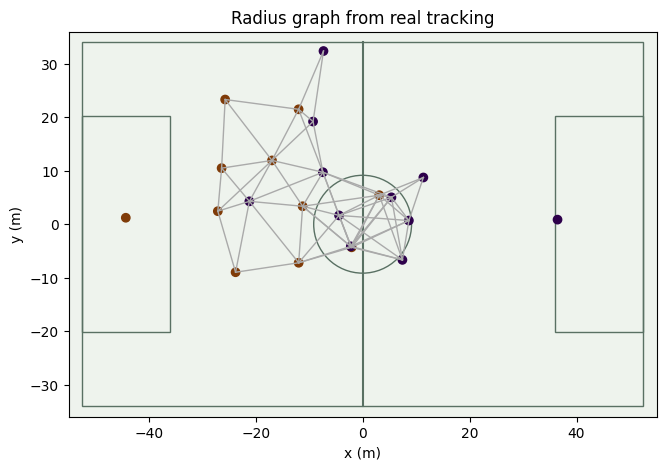

In [5]:
X,A,ids=make_graph(snapshot)
display(pd.DataFrame(X,index=ids,columns=['x_scaled','y_scaled','team']))
fig,ax=plt.subplots(figsize=(9,5))
pitch(ax)
pos=snapshot.set_index('player_id').loc[ids,['x','y']].to_numpy()
for i,j in zip(*np.where(np.triu(A>0,1))):ax.plot(pos[[i,j],0],pos[[i,j],1],c='#aaa',lw=1)
ax.scatter(pos[:,0],pos[:,1],c=X[:,2],cmap='PuOr')
ax.set_title('Radius graph from real tracking')
plt.show()

### Intermediate steps: Distance matrix, thresholded edges and normalized weights

Row normalization makes each receiving node average its neighbors. Edge choice controls whose information can reach it.

Run the helper functions, inspect their returned arrays/tables, then compare the panels in calculation order.

#### Helper: `adjacency_steps`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [6]:
def adjacency_steps(position,radius):
    distance=np.sqrt(((position[:,None]-position[None])**2).sum(axis=-1))
    binary=(distance<=radius).astype(float)
    normalized=binary/binary.sum(axis=1,keepdims=True)
    return distance,binary,normalized

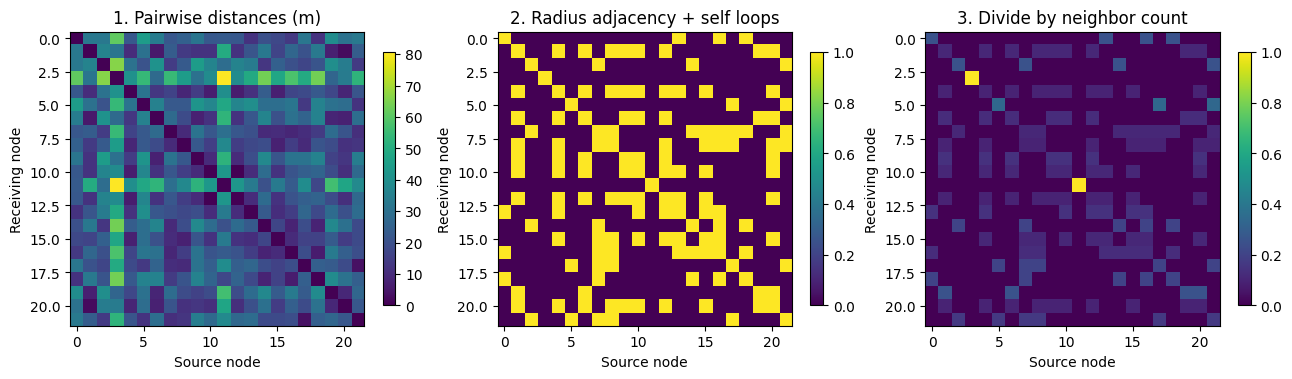

In [7]:
distance,binary,normalized=adjacency_steps(pos,15)
fig,axs=plt.subplots(1,3,figsize=(13,4))
for ax,data,title in zip(axs,[distance,binary,normalized],['1. Pairwise distances (m)','2. Radius adjacency + self loops','3. Divide by neighbor count']):
    image=ax.imshow(data,cmap='viridis');ax.set_title(title);ax.set(xlabel='Source node',ylabel='Receiving node');fig.colorbar(image,ax=ax,shrink=.7)
assert np.allclose(normalized.sum(axis=1),1)
plt.tight_layout()
plt.show()

## Message passing and graph readout
Average neighboring features, apply a learned linear map and nonlinearity, then pool player embeddings into a graph vector. Shared weights and symmetric pooling make this classifier invariant to row order when features and edges are permuted together. Distance/relative-velocity edge features and explicit ball nodes would enrich this minimal implementation.

#### Helper: `encode`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [8]:
def encode(X,A,W):return np.tanh(A@X@W)

#### Helper: `graph_probability`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [9]:
def graph_probability(X,A,W,head,bias=0):
    H=encode(X,A,W);g=H.mean(axis=0);return 1/(1+np.exp(-np.clip(g@head+bias,-40,40)))

In [10]:
rng=np.random.default_rng(4)
W=rng.normal(0,.1,(X.shape[1],8))
head=rng.normal(0,.1,8)
embedding=encode(X,A,W)
display(pd.DataFrame(embedding,index=ids).head())
permutation=rng.permutation(len(X))
assert np.isclose(graph_probability(X,A,W,head),graph_probability(X[permutation],A[np.ix_(permutation,permutation)],W,head))
print('Permutation-invariance check passed. Random weights are not EPV predictions.')

,0,1,2,3,4,5,6,7
11897,-0.010627,0.032837,-0.076271,-0.059278,0.046994,-0.020145,0.044804,-0.024377
287934,-0.158852,0.086023,-0.017431,-0.057358,-0.056208,-0.049558,0.019079,0.003939
50982,-0.054305,0.018689,-0.052488,0.052417,0.078800,0.025433,-0.049722,0.105237
50999,-0.236332,0.098342,0.082924,-0.038297,-0.176907,-0.066174,-0.009044,0.005011
51002,-0.114287,0.066750,-0.024203,-0.052994,-0.034438,-0.039754,0.022998,-0.004674


Permutation-invariance check passed. Random weights are not EPV predictions.


### Intermediate steps: Trace aggregation, learned transformation and pooling

Weights are random for this diagnostic. Inspect tensor shapes and pooling before attaching a scoring head or training a model.

Run the helper functions, inspect their returned arrays/tables, then compare the panels in calculation order.

#### Helper: `message_steps`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [11]:
def message_steps(X,A,W):
    neighbor_average=A@X
    linear=neighbor_average@W
    hidden=np.tanh(linear)
    pooled=hidden.mean(axis=0)
    return neighbor_average,linear,hidden,pooled

,node_id,own_x,neighbor_average_x,linear_channel_0,hidden_channel_0
0,11897,-0.452571,-0.399905,-0.010628,-0.010627
1,287934,0.102667,0.041989,-0.160209,-0.158852
2,50982,-0.489714,-0.385714,-0.054358,-0.054305
3,50999,0.694286,0.694286,-0.240885,-0.236332
4,51002,-0.084000,-0.028000,-0.114788,-0.114287
5,51043,-0.139429,-0.181333,-0.231112,-0.227084
6,51050,0.164762,0.064929,-0.151695,-0.150542
7,51694,-0.322857,-0.332656,-0.098002,-0.097689
8,560882,-0.141524,-0.145029,-0.142356,-0.141402
9,560983,0.141714,0.043293,-0.138079,-0.137208


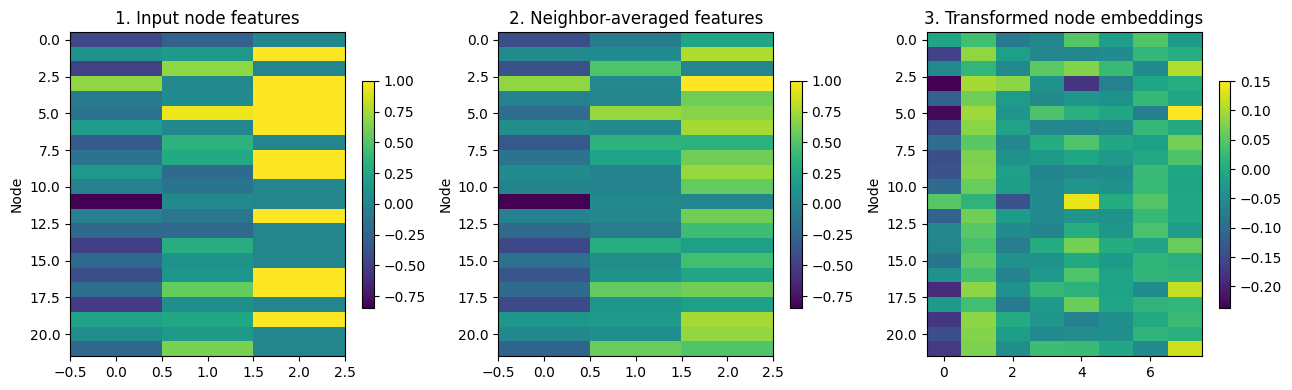

Pooling averages each embedding channel: [-0.1111  0.0614 -0.0382 -0.0273 -0.0017 -0.0246  0.0034  0.0301]


In [12]:
aggregate,linear,hidden,pooled=message_steps(X,A,W)
display(pd.DataFrame({'node_id':ids,'own_x':X[:,0],'neighbor_average_x':aggregate[:,0],'linear_channel_0':linear[:,0],'hidden_channel_0':hidden[:,0]}).head(10))
fig,axs=plt.subplots(1,3,figsize=(13,4))
for ax,data,title in zip(axs,[X,aggregate,hidden],['1. Input node features','2. Neighbor-averaged features','3. Transformed node embeddings']):
    im=ax.imshow(data,aspect='auto');ax.set_title(title);ax.set_ylabel('Node');fig.colorbar(im,ax=ax,shrink=.7)
plt.tight_layout()
plt.show()
print('Pooling averages each embedding channel:',pooled.round(4))

## Train the small GNN with explicit backpropagation
Binary cross entropy, graph pooling, tanh derivative and neighbor aggregation gradients are shown below. Training uses synthetic graphs with a synthetic feature-sign label to check that optimization works. This does **not** establish soccer performance. The same function can accept real labeled graph samples after creating an appropriate held-out split.

#### Helper: `train_gnn`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [13]:
def train_gnn(graphs,labels,hidden=8,steps=400,lr=.1):
    rng=np.random.default_rng(11);W=rng.normal(0,.2,(graphs[0][0].shape[1],hidden));head=rng.normal(0,.2,hidden);bias=0.;losses=[]
    for step in range(steps):
        dW=np.zeros_like(W);dh=np.zeros_like(head);db=0.;loss=0.
        for (X,A),y in zip(graphs,labels):
            aggregated=A@X;H=np.tanh(aggregated@W);g=H.mean(axis=0)
            z=g@head+bias;p=1/(1+np.exp(-np.clip(z,-40,40)));error=p-y
            loss+=np.logaddexp(0,z)-y*z
            dh+=g*error;db+=error
            dH=np.broadcast_to(head*error/len(X),H.shape)
            dW+=aggregated.T@(dH*(1-H**2))
        n=len(graphs);W-=lr*dW/n;head-=lr*dh/n;bias-=lr*db/n;losses.append(loss/n)
    return W,head,bias,losses

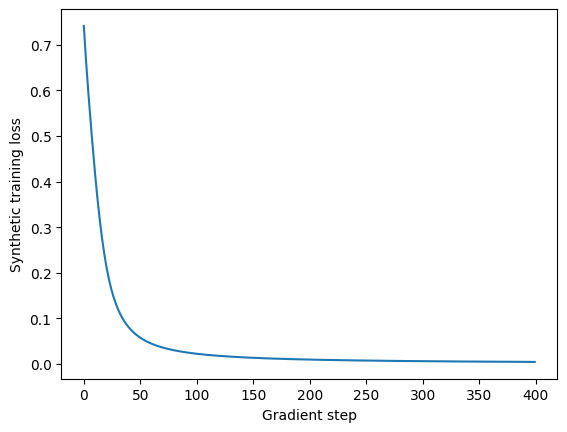

In [14]:
rng=np.random.default_rng(10)
toy_graphs=[]
toy_labels=[]
for i in range(40):
    label=i%2;features=rng.normal(2*label-1,.3,(6,3));adjacency=np.ones((6,6))/6
    toy_graphs.append((features,adjacency));toy_labels.append(label)
trained_W,trained_head,trained_bias,losses=train_gnn(toy_graphs,toy_labels)
assert losses[-1]<losses[0]
plt.plot(losses)
plt.xlabel('Gradient step')
plt.ylabel('Synthetic training loss')
plt.show()

### Intermediate steps: Inspect one backpropagation step and verify a gradient

Synthetic optimizer diagnostic only. A finite-difference check verifies that the coded derivative agrees with the actual loss calculation.

Run the helper functions, inspect their returned arrays/tables, then compare the panels in calculation order.

#### Helper: `graph_gradients`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [15]:
def graph_gradients(X,A,y,W,head,bias):
    aggregate=A@X;H=np.tanh(aggregate@W);pooled=H.mean(axis=0)
    score=pooled@head+bias;probability=1/(1+np.exp(-np.clip(score,-40,40)))
    error=probability-y
    head_gradient=pooled*error
    hidden_gradient=np.broadcast_to(error*head/len(X),H.shape)
    linear_gradient=hidden_gradient*(1-H**2)
    W_gradient=aggregate.T@linear_gradient
    loss=np.logaddexp(0,score)-y*score
    return loss,head_gradient,hidden_gradient,linear_gradient,W_gradient

,analytic,finite_difference
0,-0.069253,-0.069253


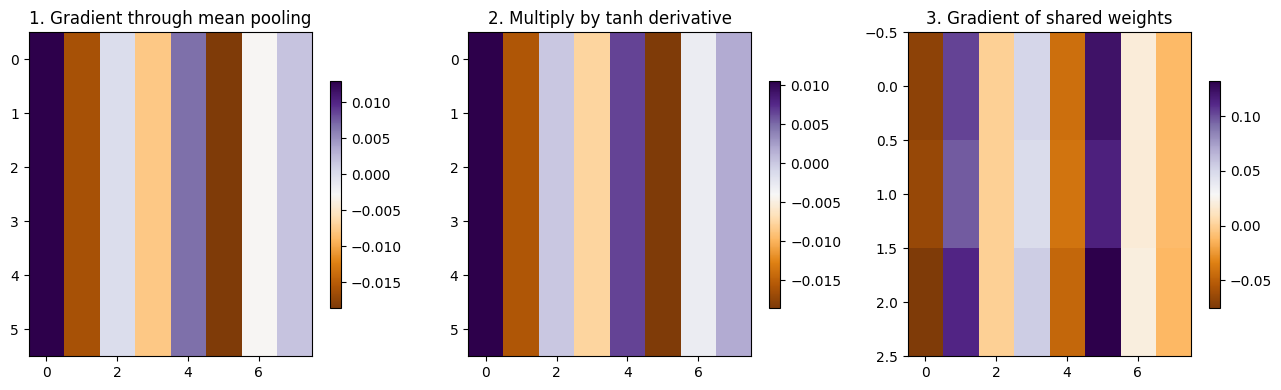

In [16]:
toy_X,toy_A=toy_graphs[0]
toy_y=0
loss,head_grad,hidden_grad,linear_grad,W_grad=graph_gradients(toy_X,toy_A,toy_y,W,head,0.)
epsilon=1e-5
plus=W.copy()
minus=W.copy()
plus[0,0]+=epsilon
minus[0,0]-=epsilon
numeric=(graph_gradients(toy_X,toy_A,toy_y,plus,head,0.)[0]-graph_gradients(toy_X,toy_A,toy_y,minus,head,0.)[0])/(2*epsilon)
assert np.isclose(numeric,W_grad[0,0],rtol=1e-4,atol=1e-7)
display(pd.DataFrame({'analytic':[W_grad[0,0]],'finite_difference':[numeric]}))
fig,axs=plt.subplots(1,3,figsize=(13,4))
for ax,data,title in zip(axs,[hidden_grad,linear_grad,W_grad],['1. Gradient through mean pooling','2. Multiply by tanh derivative','3. Gradient of shared weights']):
    im=ax.imshow(data,aspect='auto',cmap='PuOr');ax.set_title(title);fig.colorbar(im,ax=ax,shrink=.7)
plt.tight_layout()
plt.show()

## Build GraphEPV labels with a declared horizon
Bekkers' 2025 talk labels a frame positive when the team in possession scores within the next ten seconds in the same period. Require known follow-up through the horizon; censored sample endings and unknown possession must not become negative examples. Future outcomes are labels, never input features. A production implementation also needs complete event coverage and explicit period-end handling.

#### Helper: `goal_within_horizon`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [17]:
def goal_within_horizon(frames,goals,coverage_end,horizon=10):
    labels=pd.Series(np.nan,index=frames.index,dtype=float)
    for idx,r in frames.iterrows():
        end=coverage_end.get(r.period_id,-np.inf)
        if pd.isna(r.ball_owning_team_id) or r.seconds+horizon>end:continue
        eligible=goals.period.eq(r.period_id)&goals.team_id.eq(r.ball_owning_team_id)&goals.seconds.gt(r.seconds)&goals.seconds.le(r.seconds+horizon)
        labels.loc[idx]=float(eligible.any())
    return labels

In [18]:
toy_frames=pd.DataFrame({'period_id':[1,1,1],'seconds':[0,12,28],'ball_owning_team_id':[1,1,1]})
toy_goals=pd.DataFrame({'period':[1],'seconds':[8.],'team_id':[1]})
toy_labels=goal_within_horizon(toy_frames,toy_goals,{1:30.})
assert toy_labels.iloc[0]==1 and toy_labels.iloc[1]==0 and pd.isna(toy_labels.iloc[2])
display(toy_labels.rename('Synthetic target check'))

0    1.0
1    0.0
2    NaN
Name: Synthetic target check, dtype: float64

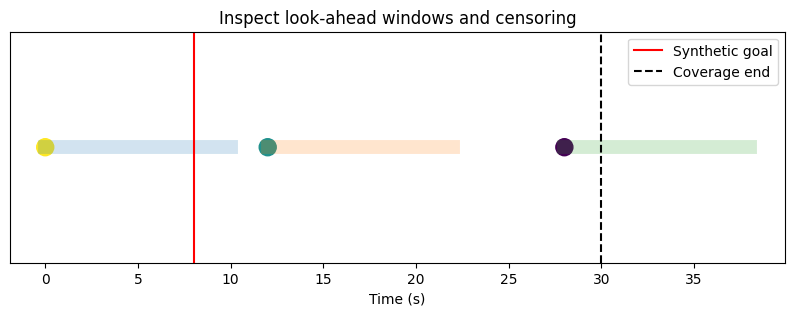

In [19]:
fig,ax=plt.subplots(figsize=(10,3))
ax.scatter(toy_frames.seconds,[0]*3,c=toy_labels.fillna(-1),cmap='viridis',s=150)
for t in toy_frames.seconds:ax.plot([t,t+10],[0,0],alpha=.2,lw=10)
ax.axvline(8,c='red',label='Synthetic goal')
ax.axvline(30,c='black',ls='--',label='Coverage end')
ax.set(xlabel='Time (s)',title='Inspect look-ahead windows and censoring',yticks=[])
ax.legend()
plt.show()

## Review the full method
Trace each final quantity back through its helper functions, intermediate arrays and visual diagnostics. Change one modeling assumption and rerun its dependent cells. Review coverage, attack direction, phase context and evaluation design before interpreting real sample results. Keep synthetic demonstrations and proxy quantities separate from trained or production model outputs.

This notebook is deliberately self-contained. Shared *concepts* such as smoothing or graph normalization are repeated inline where needed; another notebook never needs to run first.
